In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv(r'C:\Users\ASUS\OneDrive\Desktop\ICT DSA\beer-servings (1).csv', index_col = 'Unnamed: 0')

In [5]:
data.head()


,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,Albania,89.0,132.0,54.0,4.9,Europe
2,Algeria,25.0,0.0,14.0,0.7,Africa
3,Andorra,245.0,138.0,312.0,12.4,Europe
4,Angola,217.0,57.0,45.0,5.9,Africa


In [6]:
data.isna().sum()

country                         0
beer_servings                   8
spirit_servings                 8
wine_servings                   6
total_litres_of_pure_alcohol    1
continent                       0
dtype: int64

In [7]:
data.columns

Index(['country', 'beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol', 'continent'],
      dtype='str')

In [8]:
for i in ['beer_servings', 'spirit_servings', 'wine_servings','total_litres_of_pure_alcohol']:
  data[i] = data[i].fillna(data[i].median())

In [9]:
data.isna().sum()

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

In [10]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [11]:
country_encoder = LabelEncoder()
continent_encoder = LabelEncoder()

data['country'] = country_encoder.fit_transform(data['country'])
data['continent'] = continent_encoder.fit_transform(data['continent'])

In [12]:
data.head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,0.0,0.0,0.0,0.0,1
1,1,89.0,132.0,54.0,4.9,2
2,2,25.0,0.0,14.0,0.7,0
3,3,245.0,138.0,312.0,12.4,2
4,4,217.0,57.0,45.0,5.9,0


In [13]:
data.shape

(193, 6)

In [14]:
data['country'].nunique()

193

In [15]:
x = data[
    [
        'country',
        'beer_servings',
        'spirit_servings',
        'wine_servings',
        'continent'
    ]
]

y = data['total_litres_of_pure_alcohol']

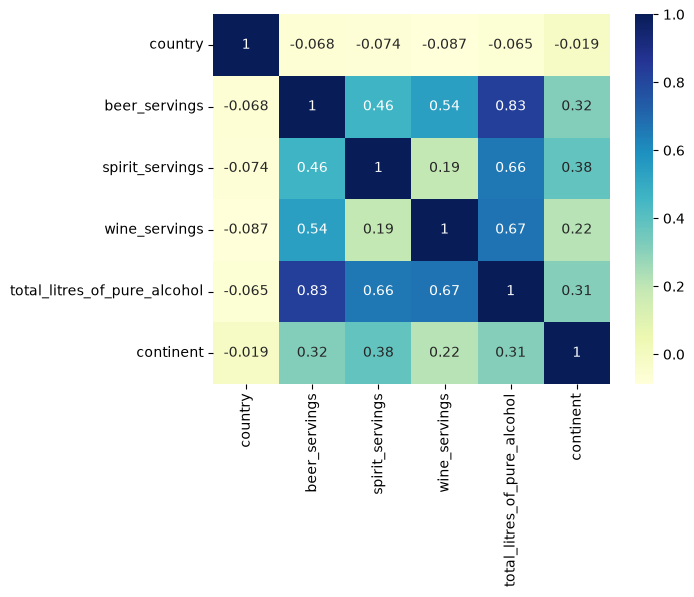

In [16]:
corr_matrix = data.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='YlGnBu')
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [18]:
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix,accuracy_score, precision_score, recall_score

In [19]:
print("Training samples:", x_train.shape[0])
print("Testing samples:", x_test.shape[0])

Training samples: 154
Testing samples: 39


In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
cols = ['beer_servings', 'spirit_servings', 'wine_servings']

In [22]:
scaler = StandardScaler()
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()
x_train_scaled[cols] = scaler.fit_transform(x_train[cols])
x_test_scaled[cols] = scaler.transform(x_test[cols])

In [23]:
from sklearn.linear_model import LinearRegression
linear_reg = LinearRegression()
linear_model = linear_reg.fit(x_train_scaled,y_train)

In [24]:
y_pred_lr = linear_model.predict(x_test_scaled)

In [25]:
linear_mse = mean_squared_error(
y_test,
y_pred_lr
)
linear_r2 = r2_score(
y_test,y_pred_lr)

In [26]:
print("Linear Regression")
print("MSE :", round(linear_mse, 2))
print("R² :", round(linear_r2, 3))

Linear Regression
MSE : 1.79
R² : 0.916


In [27]:
from sklearn.linear_model import Ridge
ridge_model = Ridge(
alpha=1.0
)
ridge_model.fit(
x_train_scaled,
y_train
)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [28]:
y_pred_ridge = ridge_model.predict(
x_test_scaled
)

In [29]:
ridge_mse = mean_squared_error(
y_test,
y_pred_ridge
)
ridge_r2 = r2_score(
y_test,y_pred_ridge)

In [30]:
print("Ridge Regression")
print("MSE :", round(ridge_mse, 2))
print("R² :", round(ridge_r2, 3))

Ridge Regression
MSE : 1.8
R² : 0.915


In [31]:
from sklearn.linear_model import Lasso
lasso_model = Lasso(
alpha=1.0
)
lasso_model.fit(
x_train_scaled,
y_train
)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [32]:
y_pred_lasso = lasso_model.predict(
x_test_scaled
)

In [33]:
lasso_mse = mean_squared_error(
y_test,
y_pred_lasso
)
lasso_r2 = r2_score(
y_test,y_pred_lasso)

In [34]:
print("Lasso Regression")
print("MSE :", round(lasso_mse, 2))
print("R² :", round(lasso_r2, 3))

Lasso Regression
MSE : 6.48
R² : 0.694


In [35]:
from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree = 2)

In [36]:
x_train_poly = poly_features.fit_transform(x_train_scaled)

In [37]:
poly_model = linear_reg.fit(x_train_poly, y_train)

In [38]:
x_test_poly = poly_features.transform(x_test_scaled)

In [39]:
y_pred_pr = poly_model.predict(x_test_poly)

In [40]:
poly_mse = mean_squared_error(
y_test,
y_pred_pr
)
poly_r2 = r2_score(
y_test,y_pred_pr)

In [41]:
print("Polynomial Regression")
print("MSE :", round(poly_mse, 2))
print("R² :", round(poly_r2, 3))

Polynomial Regression
MSE : 1.94
R² : 0.909


In [42]:
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(
max_depth=8,
random_state=42
)

In [43]:
dt_model.fit(
x_train,
y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

In [44]:
y_pred_dt = dt_model.predict(
x_test
)

In [45]:
dt_mse = mean_squared_error(
y_test,
y_pred_dt
)
dt_r2 = r2_score(
y_test,y_pred_dt)

In [46]:
print("Decision Tree Regression")
print("MSE :", round(dt_mse, 2))
print("R² :", round(dt_r2, 3))

Decision Tree Regression
MSE : 5.45
R² : 0.743


In [47]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
n_estimators=200,
random_state=42
)

In [48]:
rf_model.fit(
x_train,
y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [49]:
y_pred_rf = rf_model.predict(
x_test
)

In [50]:
rf_mse = mean_squared_error(
y_test,
y_pred_rf
)
rf_r2 = r2_score(
y_test,y_pred_rf)

In [51]:
print("Random Forest Regression")
print("MSE :", round(rf_mse, 2))
print("R² :", round(rf_r2, 3))

Random Forest Regression
MSE : 3.92
R² : 0.815


In [52]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 8, 10, None]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1
)


grid_search.fit(x_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation R²:", grid_search.best_score_)


Best parameters: {'max_depth': 8, 'n_estimators': 200}
Best cross-validation R²: 0.7660493839832252


In [53]:

best_rf_model = grid_search.best_estimator_

y_pred_rf_tuned = best_rf_model.predict(x_test)

rf_tuned_mse = mean_squared_error(y_test, y_pred_rf_tuned)
rf_tuned_r2 = r2_score(y_test, y_pred_rf_tuned)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation R²:", grid_search.best_score_)
print("Tuned Random Forest Test MSE:", rf_tuned_mse)
print("Tuned Random Forest Test R²:", rf_tuned_r2)


Best Parameters: {'max_depth': 8, 'n_estimators': 200}
Best Cross-Validation R²: 0.7660493839832252
Tuned Random Forest Test MSE: 3.9995271744865577
Tuned Random Forest Test R²: 0.8111779236926451


In [54]:
results = pd.DataFrame({
"Model": [
"Linear Regression",
"Ridge Regression",
"Lasso Regression",
"Polynomial Regression",
"Decision Tree",
"Random Forest"
],
"MSE": [
linear_mse,
ridge_mse,
lasso_mse,
poly_mse,
dt_mse,
rf_mse
],
"R2": [
linear_r2,
ridge_r2,
lasso_r2,
poly_r2,
dt_r2,
rf_r2
]
})
results

,Model,MSE,R2
0,Linear Regression,1.788093,0.915582
1,Ridge Regression,1.801983,0.914926
2,Lasso Regression,6.476261,0.694249
3,Polynomial Regression,1.937522,0.908527
4,Decision Tree,5.447009,0.742841
5,Random Forest,3.918699,0.814994


In [55]:
tuned_result = pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "MSE": [rf_tuned_mse],
    "R2": [rf_tuned_r2]
})

all_results = pd.concat(
    [results, tuned_result],
    ignore_index=True
)

print(all_results)

                   Model       MSE        R2
0      Linear Regression  1.788093  0.915582
1       Ridge Regression  1.801983  0.914926
2       Lasso Regression  6.476261  0.694249
3  Polynomial Regression  1.937522  0.908527
4          Decision Tree  5.447009  0.742841
5          Random Forest  3.918699  0.814994
6    Tuned Random Forest  3.999527  0.811178


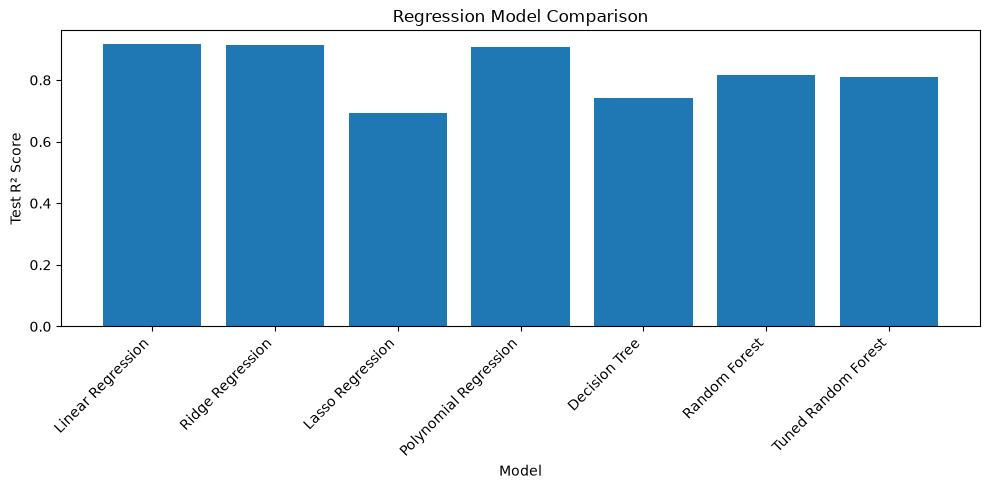

In [56]:
plt.figure(figsize=(10, 5))

plt.bar(
    all_results["Model"],
    all_results["R2"]
)

plt.title("Regression Model Comparison")
plt.xlabel("Model")
plt.ylabel("Test R² Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [57]:
results_sorted = all_results.sort_values(
    by="R2",
    ascending=False
)

best_model_name = results_sorted.iloc[0]["Model"]
best_test_r2 = results_sorted.iloc[0]["R2"]

print("Best model:", best_model_name)
print("Best test R²:", round(best_test_r2, 4))

Best model: Linear Regression
Best test R²: 0.9156


In [69]:
import joblib

artifacts = {
    "model": linear_model,
    "scaler": scaler,
    "country_encoder": country_encoder,
    "continent_encoder": continent_encoder,
    "numerical_columns": [
        "beer_servings",
        "spirit_servings",
        "wine_servings"
    ],
    "feature_columns": [
        "country",
        "beer_servings",
        "spirit_servings",
        "wine_servings",
        "continent"
    ]
}

joblib.dump(artifacts, "model.pkl")

print("Model and encoders saved successfully!")

Model and encoders saved successfully!


In [73]:

import joblib
import os

save_path = r"C:\Users\ASUS\OneDrive\Desktop\ICT DSA\HTML and CSS\Beer Serving\model.pkl"

# Confirm the correct model before saving
print("Model to save:", flask_model.n_features_in_)

assert flask_model.n_features_in_ == 5, "Wrong model selected!"

artifacts = {
    "model": flask_model,
    "scaler": scaler,
    "country_encoder": country_encoder,
    "continent_encoder": continent_encoder
}

joblib.dump(artifacts, save_path)

# Load the file again to verify
check = joblib.load(save_path)

print("Saved model features:", check["model"].n_features_in_)
print("File size:", os.path.getsize(save_path), "bytes")



Model to save: 5
Saved model features: 5
File size: 4401 bytes
